# Session 1: Why Vote, the Central Binomial Term and Stirling's Approximation

*ECE 225A, Module 02 (Binomial and Geometric Applications), deck 2.Why_vote, slides 1-12*

Many people skip voting because one ballot "cannot change anything". This session turns that claim into a number. With $2n + 1$ voters, your vote decides the election exactly when the other $2n$ split evenly, so the chance you matter is a single binomial probability, $\binom{2n}{n}/2^{2n}$. The formula is exact but says little about large $n$. Stirling's approximation for $n!$ turns it into the simple rate $1/\sqrt{\pi n}$, which is far larger than most guesses. The session closes with an argument that explains the $1/\sqrt{n}$ without any heavy computation: it comes from the standard deviation of the binomial. That argument returns in Module 04, where it becomes the height of the normal curve.

## Learning objectives

After this session you should be able to:

1. Model "your vote decides" as an event and reduce it to an even split of the other voters.
2. Write the decisive probability as $b_{1/2,\,2n}(n) = \binom{2n}{n}/2^{2n}$, and recognize the same number in coin flips and random walks.
3. State Stirling's approximation and use it to derive $\binom{2n}{n}/2^{2n} \approx 1/\sqrt{\pi n}$.
4. Compare the rate $1/\sqrt{n}$ with the common guesses $1/n$, $1/n^2$, and $1/2^n$, and apply it to real electorate sizes.
5. Explain the rate through the standard deviation: the binomial spreads over about $\sqrt{n}$ likely values, so each one gets about $1/\sqrt{n}$.

## Prerequisites

- Binomial distribution, PMF, mean $np$, and variance $npq$ (Module 01, Session 5).
- Independence and the product rule (Module 01, Session 2).
- Calculus: the meaning of a limit and of asymptotic equivalence.

In [1]:
from fractions import Fraction
from math import comb, e, exp, lgamma, log, pi, sqrt

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(225)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, FAINT, GRID = "#0b0b0b", "#52514e", "#c3c2b7", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})


def show(label, v):
    # Print an exact value as a fraction and as a decimal.
    print(f"{label}: {v} = {float(v):.6f}")


def decisive(n):
    # P(the other 2n voters split evenly), as an exact fraction.
    return Fraction(comb(2 * n, n), 4 ** n)

## 1. The question and the model (slides 1-3)

**Intuition.** Before computing anything, we need to say what "your vote decides the election" means. It does not mean you are the last person to vote. It means that the result with your vote differs from the result without it. Equivalently, you hold a veto: if you vote D then D wins, and if you vote R then R wins.

**Model.** Assume there are two parties, D and R, and that every other voter picks one of them independently and with equal probability. Equal likelihood is a simplification, and it is the most favorable case for being decisive. Exercise 7 shows what happens without it.

**Formal definition.** With $N$ voters in total, the event "you decide" is

$$\lbrace \text{the winner would be D if you vote D, and R if you vote R} \rbrace.$$

To avoid draws in the final count, take $N$ odd. Then the other $N - 1$ voters are an even number, and your vote is decisive exactly when they split evenly.

## 2. Small cases and a guess (slide 4)

Work up from the smallest electorates:

- **1 voter (you).** You determine the outcome, so the probability is 1.
- **2 voters.** A draw is possible, which complicates the bookkeeping. Section 8 returns to this case.
- **3 voters.** You decide exactly when the other two disagree. Their votes are DD, DR, RD, or RR with equal probability, and two of the four are splits, so the probability is $1/2$.

From now on, take an odd number of voters, $2n + 1$. Before reading on, guess how $P(\text{your vote matters})$ behaves for large $n$. Is it constant like $1/2$, or like $1/\sqrt{n}$, $1/n$, $1/n^2$, or $1/2^n$? Most people pick one of the last three.

In [2]:
from itertools import product

other_two = list(product("DR", repeat=2))
splits = [votes for votes in other_two if votes.count("D") == 1]
print("the other two vote:", ["".join(v) for v in other_two])
print("even splits:       ", ["".join(v) for v in splits])
show("P(you decide), 3 voters", Fraction(len(splits), len(other_two)))

the other two vote: ['DD', 'DR', 'RD', 'RR']
even splits:        ['DR', 'RD']
P(you decide), 3 voters: 1/2 = 0.500000


## 3. The exact formula (slide 5)

Let $X$ be the number of the other $2n$ voters who choose D. Then $X \sim B_{1/2,\,2n}$, and you decide exactly when $X = n$. Substituting $p = q = 1/2$ into the binomial PMF:

$$P(\text{you decide}) = b_{1/2,\,2n}(n) = \binom{2n}{n} \cdot \frac{1}{2^n} \cdot \frac{1}{2^n} = \frac{(2n)!}{(n!)^2} \cdot \frac{1}{2^{2n}}.$$

The same number appears elsewhere under other names:

- **Coins.** It is the probability of exactly $n$ heads in $2n$ fair flips.
- **Random walk.** A walker steps $+1$ or $-1$ with equal probability. It is back at 0 after $2n$ steps exactly when $n$ of the steps were $+1$, so this is also $P(\text{at 0 after } 2n \text{ steps})$. The slide calls the walker Dr. Unkard. A walker cannot be at 0 after an odd number of steps.

The formula is exact, but it does not reveal how the probability relates to a rate such as $1/2^n$.

In [3]:
n, trials = 10, 1_000_000
heads = rng.binomial(2 * n, 0.5, size=trials)
steps = 2 * rng.integers(0, 2, size=(200_000, 2 * n)) - 1

show("exact, 2n = 20", decisive(n))
print(f"simulated 20 coins, exactly 10 heads: {np.mean(heads == n):.6f}")
print(f"simulated random walk, at 0 after 20 steps: {np.mean(steps.sum(axis=1) == 0):.6f}")

exact, 2n = 20: 46189/262144 = 0.176197
simulated 20 coins, exactly 10 heads: 0.176090
simulated random walk, at 0 after 20 steps: 0.176855


## 4. Small $n$ (slide 6)

Evaluating the formula for a few values:

| $n$ | Voters | Term | Expression | Probability |
|---|---|---|---|---|
| 1 | 3 | $b_{1/2,\,2}(1)$ | $\frac{2!}{(1!)^2} \cdot \frac{1}{2^2}$ | $1/2$ |
| 2 | 5 | $b_{1/2,\,4}(2)$ | $\frac{4!}{(2!)^2} \cdot \frac{1}{2^4}$ | $3/8 = 0.375$ |
| 10 | 21 | $b_{1/2,\,20}(10)$ | $\frac{20!}{(10!)^2} \cdot \frac{1}{2^{20}}$ | $\approx 0.176$ |

If the decay were exponential like $1/2^n$, then $n = 10$ would give about $0.001$. The real value is 180 times larger, so the behavior is not exponential. We need a tool that handles the factorials for large $n$.

In [4]:
print(" n   voters   exact              1/2^n")
for n in [1, 2, 3, 5, 10, 20]:
    p = decisive(n)
    print(f"{n:2d}   {2 * n + 1:6d}   {float(p):.6f}           {2.0 ** -n:.6f}")

 n   voters   exact              1/2^n
 1        3   0.500000           0.500000
 2        5   0.375000           0.250000
 3        7   0.312500           0.125000
 5       11   0.246094           0.031250
10       21   0.176197           0.000977
20       41   0.125371           0.000001


## 5. Stirling's approximation (slide 7)

**Intuition.** The factorial grows roughly like $(n/e)^n$, with a slowly growing correction factor of order $\sqrt{n}$. In $\binom{2n}{n}/2^{2n}$ the large powers cancel, and only the correction factors survive.

**Formal statement.** Stirling's approximation says

$$n! \approx \sqrt{2\pi n} \left(\frac{n}{e}\right)^n,$$

in the sense that the ratio of the two sides tends to 1 as $n \to \infty$.

**Applying it to our term.** Substitute into the numerator with $2n$ and into the denominator with $n$:

$$\frac{(2n)!}{(n!)^2 \, 2^{2n}} \approx \frac{\sqrt{2\pi \cdot 2n} \, (2n/e)^{2n}}{\left[\sqrt{2\pi n} \, (n/e)^n\right]^2 2^{2n}}.$$

Now cancel in three steps:

1. The powers of $n$ and $e$: $(2n/e)^{2n} = 2^{2n} (n/e)^{2n}$, and $(n/e)^{2n}$ also appears in the denominator.
2. The factor $2^{2n}$ from step 1 cancels the $2^{2n}$ in the denominator.
3. The square roots leave $\sqrt{4\pi n} / (2\pi n) = 2\sqrt{\pi n} / (2\pi n) = 1/\sqrt{\pi n}$.

The result is the headline formula of this session:

$$P(\text{you decide}) \approx \frac{1}{\sqrt{\pi n}}.$$

**Check at $n = 10$.** The approximation gives $1/\sqrt{10\pi} \approx 0.178$, which is about 1% above the exact $0.176$, and the gap shrinks as $n$ grows.

**Morals.** The probability falls like $1/\sqrt{n}$, which is far slower than $1/n$. This is also a small lesson in theory: we started with no idea of the answer, derived an exact formula, and then extracted its rate.

In [5]:
print("  n     n!/Stirling     exact term      1/sqrt(pi n)    approx/exact")
for n in [1, 2, 5, 10, 50, 100, 500]:
    # Compare in logs, since (n/e)^n overflows a float at n = 500.
    ratio = exp(lgamma(n + 1) - (0.5 * log(2 * pi * n) + n * log(n / e)))
    p, approx = float(decisive(n)), 1 / sqrt(pi * n)
    print(f"{n:4d}   {ratio:12.6f}   {p:12.6f}   {approx:12.6f}   {approx / p:12.6f}")

  n     n!/Stirling     exact term      1/sqrt(pi n)    approx/exact
   1       1.084438       0.500000       0.564190       1.128379
   2       1.042207       0.375000       0.398942       1.063846
   5       1.016784       0.246094       0.252313       1.025273
  10       1.008365       0.176197       0.178412       1.012573
  50       1.001668       0.079589       0.079788       1.002503
 100       1.000834       0.056348       0.056419       1.001251
 500       1.000167       0.025225       0.025231       1.000250


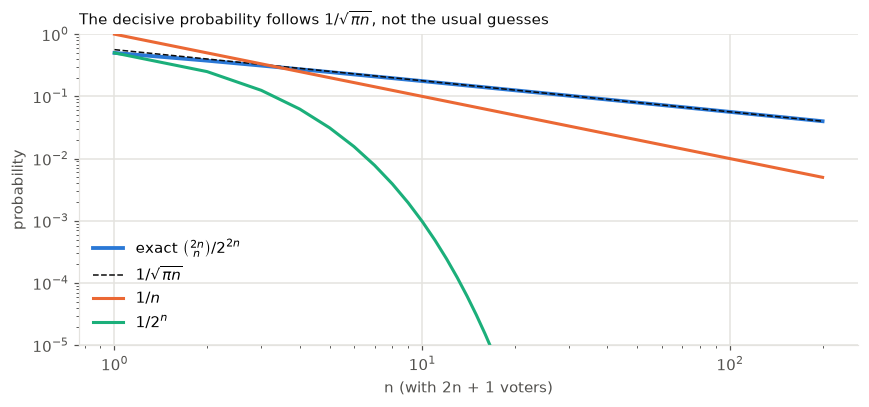

In [6]:
ns = np.arange(1, 201)
exact = np.array([float(decisive(int(n))) for n in ns])

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.loglog(ns, exact, color=BLUE, lw=2.5, label="exact $\\binom{2n}{n}/2^{2n}$")
ax.loglog(ns, 1 / np.sqrt(pi * ns), color=INK, lw=1, ls="--", label="$1/\\sqrt{\\pi n}$")
ax.loglog(ns, 1 / ns, color=ORANGE, lw=2, label="$1/n$")
ax.loglog(ns, 0.5 ** ns.clip(max=60), color=AQUA, lw=2, label="$1/2^n$")
ax.set(xlabel="n (with 2n + 1 voters)", ylabel="probability", ylim=(1e-5, 1))
ax.legend(frameon=False)
ax.set_title("The decisive probability follows $1/\\sqrt{\\pi n}$, not the usual guesses", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

On log-log axes a power law is a straight line with slope equal to its exponent. The exact curve and $1/\sqrt{\pi n}$ overlap almost completely with slope $-1/2$, while $1/n$ has slope $-1$ and $1/2^n$ plunges out of the frame.

## 6. Numerology (slide 8)

Take $n = 3{,}200$, so there are $2n + 1 = 6{,}401$ voters. Then

$$P(\text{you decide}) \approx \frac{1}{\sqrt{\pi n}} = \frac{1}{\sqrt{3200\pi}} \approx \frac{1}{\sqrt{10{,}053}} \approx \frac{1}{100}.$$

In a town of 6,401 voters, your vote decides the election about once in 100 elections. That is 64 times larger than the "fair share" guess $1/6401$:

$$\frac{1}{100} \gg \frac{1}{6401}.$$

In [7]:
n = 3200
exact = comb(2 * n, n) / 4 ** n
print(f"exact: {exact:.6f}, approximation: {1 / sqrt(pi * n):.6f}, one in {1 / exact:.1f}")
print(f"fair share 1/6401: {1 / 6401:.6f}, ratio to exact: {exact * 6401:.1f}")

exact: 0.009973, approximation: 0.009974, one in 100.3
fair share 1/6401: 0.000156, ratio to exact: 63.8


## 7. Intuition without Stirling (slide 9)

Stirling gives the rate, but it does not explain it. A short argument does, and it needs only the mean and the standard deviation.

Let $X \sim B_{1/2,\,n}$, so $n$ voters instead of $2n$, and we ask about the central value $n/2$. Stirling (with $2n$ replaced by $n$) gives

$$b_{1/2,\,n}(n/2) \approx \sqrt{\frac{2}{\pi n}} = \frac{\sqrt{2/\pi}}{\sqrt{n}}.$$

Now forget Stirling and reason like this:

1. **Center.** The mean is $\mu = np = n/2$.
2. **Spread.** The standard deviation is $\sigma = \sqrt{npq} = \sqrt{n \cdot (1/2)^2} = \frac{1}{2}\sqrt{n}$.
3. **Likely values.** $X$ is usually within about one standard deviation of the mean, so the typical values lie in $n/2 \pm \frac{1}{2}\sqrt{n}$.
4. **Width.** That range contains about $2 \cdot \frac{1}{2}\sqrt{n} = \sqrt{n}$ values.
5. **Share.** The value $n/2$ is one of about $\sqrt{n}$ outcomes of similar probability, so it receives about $1/\sqrt{n}$.

The answer is off by only the constant $\sqrt{2/\pi} \approx 0.8$, but it has the correct rate and a clear reason: **the peak probability is about $1/\sigma$**.

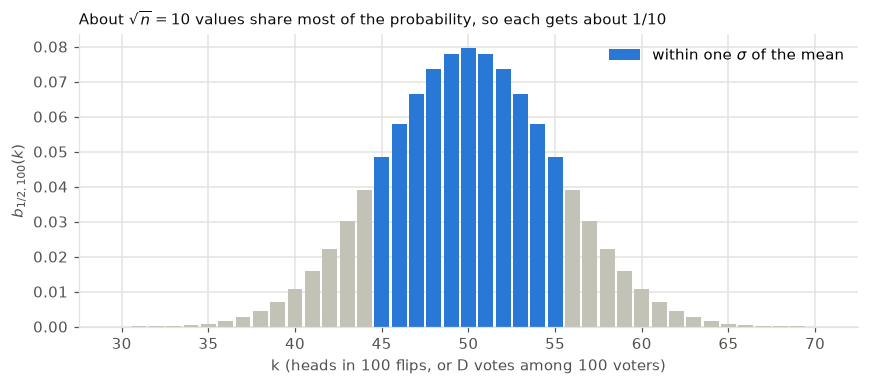

P(within one sigma): 0.7287  (11 values)
peak probability: 0.0796, heuristic 1/sqrt(n): 0.1000, Stirling sqrt(2/(pi n)): 0.0798


In [8]:
n = 100
ks = np.arange(30, 71)
probs = np.array([comb(n, int(k)) / 2 ** n for k in ks])
mu, sigma = n / 2, sqrt(n) / 2

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(ks, probs, width=0.86, color=FAINT)
inside = np.abs(ks - mu) <= sigma
ax.bar(ks[inside], probs[inside], width=0.86, color=BLUE, label="within one $\\sigma$ of the mean")
ax.set(xlabel="k (heads in 100 flips, or D votes among 100 voters)", ylabel="$b_{1/2,100}(k)$")
ax.legend(frameon=False, loc="upper right")
ax.set_title("About $\\sqrt{n} = 10$ values share most of the probability, so each gets about $1/10$", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

print(f"P(within one sigma): {probs[inside].sum():.4f}  (11 values)")
print(f"peak probability: {probs.max():.4f}, heuristic 1/sqrt(n): {1 / sqrt(n):.4f}, Stirling sqrt(2/(pi n)): {sqrt(2 / (pi * n)):.4f}")

## 8. An even number of voters (slide 10)

With $2n$ voters, a draw has probability

$$b_{1/2,\,2n}(n) \approx \frac{1}{\sqrt{\pi n}},$$

which is the same expression as before. Your vote among $2n + 1$ voters decides exactly when the other $2n$ would tie by themselves. So a tied election is also far more likely than one might expect.

In [9]:
for voters in [100, 10_000, 1_000_000]:
    n = voters // 2
    print(f"{voters:>9,d} voters: P(draw) is about {1 / sqrt(pi * n):.6f}, one in {sqrt(pi * n):,.0f}")

      100 voters: P(draw) is about 0.079788, one in 13
   10,000 voters: P(draw) is about 0.007979, one in 125
1,000,000 voters: P(draw) is about 0.000798, one in 1,253


## 9. Ties really happen (slide 11)

This is not only a theoretical point. In a 2017 race for the Virginia House of Delegates, the two leading candidates finished in an exact tie. The slide reports 23,216 votes in total. It also shows 12,608 votes per candidate, which cannot be right, since $2 \cdot 12{,}608 = 25{,}216$. An even split of 23,216 votes is 11,608 each.

Treat those votes as $2n = 23{,}216$ fair coin flips. Then

$$P(\text{draw}) \approx \frac{1}{\sqrt{11{,}608\pi}} \approx 0.0052,$$

or about 1 in 190. There are thousands of races at this scale, so an occasional exact tie should not be a surprise. The model does assume an even contest, and Exercise 7 shows how much that assumption matters.

In [10]:
n = 11_608
approx = 1 / sqrt(pi * n)
print(f"P(draw) with {2 * n:,d} votes: {approx:.6f}, one in {1 / approx:.0f}")
print(f"each single vote is a fair share of only {1 / (2 * n):.6f}")

P(draw) with 23,216 votes: 0.005237, one in 191
each single vote is a fair share of only 0.000043


## Common pitfalls

1. **Treating your influence as $1/N$.** Being decisive is not a fair division of power. Its probability scales as $1/\sqrt{N}$, because it depends on the spread of the count rather than on the number of voters.
2. **Confusing the two meanings of $n$.** There are $2n + 1$ voters, and $n$ is half of the others. For 6,401 voters, $n = 3{,}200$. Substituting $N$ for $n$ gives the wrong constant.
3. **Forgetting that equal likelihood is doing the work.** The rate $1/\sqrt{\pi n}$ needs $p = 1/2$. With $p \ne 1/2$, the probability is exponentially small (Exercise 7).
4. **Reading "$\approx$" in Stirling as a small absolute error.** The ratio tends to 1, but the difference $n! - \sqrt{2\pi n}(n/e)^n$ grows without bound. Use it in products and ratios.
5. **Dropping the $\sqrt{\phantom{n}}$ when combining factorials.** Squaring $n!$ squares the $\sqrt{2\pi n}$ too, and that is where the $\pi n$ comes from.
6. **Expecting a random walk at 0 after an odd number of steps.** That is impossible. The formula applies only to an even number of steps.

## Key takeaways

- **Model:** with $2n + 1$ voters and each other voter fair and independent, you decide exactly when the other $2n$ split evenly.
- **Exact value:** $P(\text{you decide}) = b_{1/2,\,2n}(n) = \binom{2n}{n}/2^{2n}$. Examples: $1/2$, $3/8$, and about $0.176$ for $n = 1, 2, 10$.
- **Stirling:** $n! \approx \sqrt{2\pi n}\,(n/e)^n$, with ratio tending to 1.
- **Rate:** $\binom{2n}{n}/2^{2n} \approx 1/\sqrt{\pi n}$, which is far above $1/n$. For 6,401 voters it is about $1/100$.
- **Why:** the binomial has $\sigma = \sqrt{n}/2$, so about $\sqrt{n}$ values share the probability and the central one gets about $1/\sigma$.
- **Even electorates:** a draw among $2n$ voters has the same probability, and exact ties do occur in practice.
- Next: Session 2 turns to the geometric distribution with two more applied problems. The $1/\sigma$ peak returns in Module 04, Session 3 as the height of the normal approximation to the binomial.